In [1]:
### follow the notebook to see change of spin splitting vs longitudinal length

In [2]:
import time
import sys
import os

# Add the parent directory to sys.path
notebook_path = os.getcwd()  # Get the current working directory where the notebook is located
parent_directory = os.path.dirname(notebook_path)  # Move to the parent directory
sys.path.append(parent_directory)

# Now you can import config
from config import *
import Minimal_Model_1D as M
import time

np.set_printoptions(threshold=sys.maxsize)

In [16]:
### Plotting spin splitting while varying Lsm ###

#NSM = 60          # in nm
#MY = 2             # no of subbands
AX = 5             # lattice spacing in nm
DELTA = 0.165      # in meV
#MEFF_SC = 0.05     # Ge
#MEFF_SM = 0.05     # Proximitized Ge
MEFF_SC = 0.023     # InAs
MEFF_SM = 0.023     # InAs

NSC = 400

NSM = np.arange(100, 400, 2, dtype=int)

N = 2*NSC + NSM

PHI = 0.5*np.pi 

#print('first subband energy =' , OMEGA , '\n', 'second subband energy =' , 2*OMEGA)

ALPHAT = 400  #meV-nm # 20 is within perturbative regime for widths atleast up to 100 nm

#LY = np.linspace(20, 100, 51)

#M = np.arange(4, 20, 1, dtype=int )


LY = 20
AY = 5 

MY = 3 

OMEGA = 2*4*hbm/LY**2/MEFF_SC

MU_SM = 0.8 + OMEGA/2        ## As per Andreev Aprroximation chemical pot >> superconducting gap 
MU_SC = 0.8 + OMEGA/2        ## constant potential over reference level across all widths

K_NUM = 8


print('lengths=', NSM*AX)

print('subband energies=', OMEGA/2, 3*OMEGA/2)

print('4t=', 4*hbm/AX**2/MEFF_SM)

print('mu = ', MU_SM)


lengths= [ 500  510  520  530  540  550  560  570  580  590  600  610  620  630
  640  650  660  670  680  690  700  710  720  730  740  750  760  770
  780  790  800  810  820  830  840  850  860  870  880  890  900  910
  920  930  940  950  960  970  980  990 1000 1010 1020 1030 1040 1050
 1060 1070 1080 1090 1100 1110 1120 1130 1140 1150 1160 1170 1180 1190
 1200 1210 1220 1230 1240 1250 1260 1270 1280 1290 1300 1310 1320 1330
 1340 1350 1360 1370 1380 1390 1400 1410 1420 1430 1440 1450 1460 1470
 1480 1490 1500 1510 1520 1530 1540 1550 1560 1570 1580 1590 1600 1610
 1620 1630 1640 1650 1660 1670 1680 1690 1700 1710 1720 1730 1740 1750
 1760 1770 1780 1790 1800 1810 1820 1830 1840 1850 1860 1870 1880 1890
 1900 1910 1920 1930 1940 1950 1960 1970 1980 1990]
subband energies= 16.579300334086994 49.73790100226098
4t= 265.2688053453919
mu =  17.379300334086995


In [17]:
Ep_cu = np.empty((NSM.shape[0],K_NUM) )
#Kappa = np.empty((LY.shape[0],1) )

for i in range(NSM.shape[0]):

    Fcu = M.oneD_Minimal_Model(N[i],NSM[i], NSC,MY,AX ,OMEGA, ALPHAT, DELTA, MEFF_SC, MEFF_SM, MU_SC, MU_SM)
    #Kappa[i] = Fli.Ky_pr(1,2).real*ALPHAT/OMEGA[i]
    
    Hcu = Fcu.H_sys(PHI, so = 'cu')
    
    Ecu = eigsh(Hcu ,k=K_NUM,sigma=0, return_eigenvectors=False)
    
    Ecu = np.sort(Ecu)
    
    Ep_cu[i,:] = Ecu 
    
    if i%10==0:
        print(i)

0
10
20
30
40
50
60
70
80
90
100
110
120
130
140


In [18]:
np.save("cubic_spin_Splitting_1d_model_lsm_from_{}_to_{}_step_{}".format(NSM[0]*AX, NSM[-1]*AX, (NSM[1]-NSM[0])*AX), Ep_cu)

Text(0, 0.5, 'spin splitting(meV)')

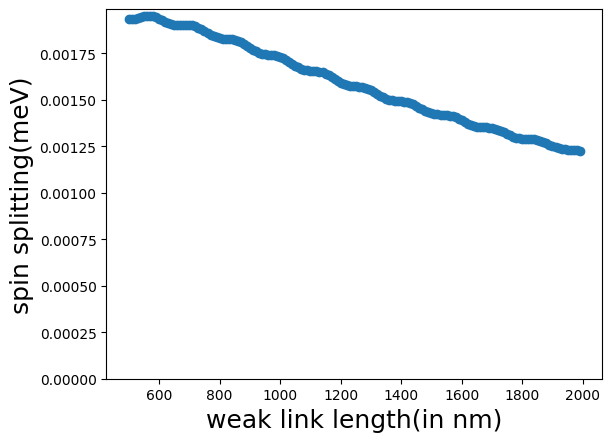

In [19]:
plt.scatter(NSM*AX, (Ep_cu[:,K_NUM//2+1]-Ep_cu[:,K_NUM//2])/DELTA)
plt.ylim(ymin=0)
plt.xlabel(r"weak link length(in nm)", fontsize=18)
plt.ylabel("spin splitting(meV)", fontsize=18)

Text(0, 0.5, 'spin splitting(meV)')

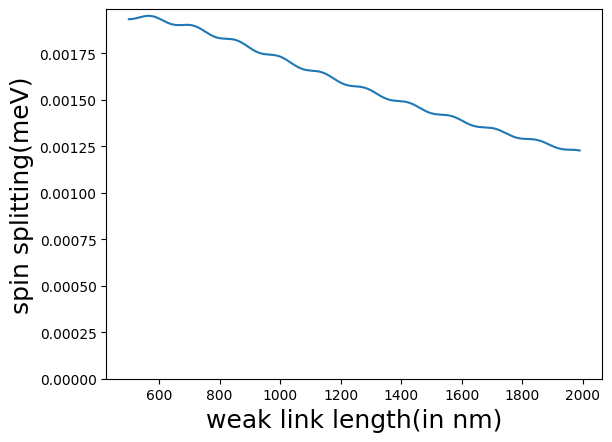

In [20]:
plt.plot(NSM*AX, (Ep_cu[:,K_NUM//2+1]-Ep_cu[:,K_NUM//2])/DELTA)
plt.ylim(ymin=0)
plt.xlabel(r"weak link length(in nm)", fontsize=18)
plt.ylabel("spin splitting(meV)", fontsize=18)

In [21]:
ALPHAT=20
MY=5

Ep_li = np.empty((NSM.shape[0],K_NUM) )
#Kappa = np.empty((LY.shape[0],1) )

for i in range(NSM.shape[0]):

    Fli = M.oneD_Minimal_Model(N[i],NSM[i], NSC,MY,AX ,OMEGA, ALPHAT, DELTA, MEFF_SC, MEFF_SM, MU_SC, MU_SM)
    #Kappa[i] = Fli.Ky_pr(1,2).real*ALPHAT/OMEGA[i]
    
    Hli = Fli.H_sys(PHI, so = 'li')
    
    Eli = eigsh(Hli ,k=K_NUM,sigma=0, return_eigenvectors=False)
    
    Eli = np.sort(Eli)
    
    Ep_li[i,:] = Eli 
    
    if i%10==0:
        print(i)

0
10
20
30
40
50
60
70
80
90
100
110
120
130
140


In [22]:
np.save("linear_spin_Splitting_1d_model_lsm_from_{}_to_{}_step_{}".format(NSM[0]*AX, NSM[-1]*AX,((NSM[1]-NSM[0])*AX) ), Ep_li)

Text(0, 0.5, 'spin splitting(meV)')

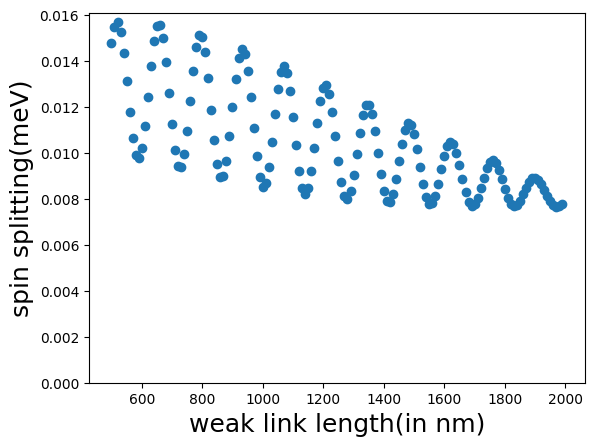

In [23]:
plt.scatter(NSM*AX, (Ep_li[:,K_NUM//2+1]-Ep_cu[:,K_NUM//2])/DELTA)
plt.ylim(ymin=0)
plt.xlabel(r"weak link length(in nm)", fontsize=18)
plt.ylabel("spin splitting(meV)", fontsize=18)

Text(0, 0.5, 'spin splitting(meV)')

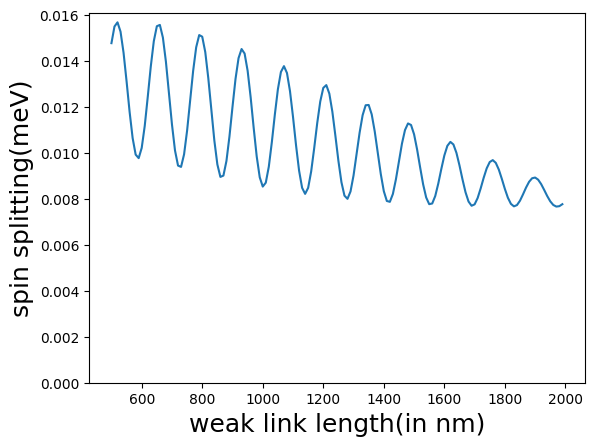

In [24]:
plt.plot(NSM*AX, (Ep_li[:,K_NUM//2+1]-Ep_cu[:,K_NUM//2])/DELTA)
plt.ylim(ymin=0)
plt.xlabel(r"weak link length(in nm)", fontsize=18)
plt.ylabel("spin splitting(meV)", fontsize=18)